NAME-DEVADHARSHINI M

PROJECT NAME- Movie Rating Prediction with Python

In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

url = "https://raw.githubusercontent.com/devadharshinimurugan06-commits/CODSOFT_TASKS_Devadharshini/main/Task2_Movie_Rating_Prediction/IMDb%20Movies%20India.csv"


df = pd.read_csv(url, encoding='latin-1')
print("Shape:", df.shape)

Shape: (15509, 10)


In [57]:
df.head()

,Name,Year,Duration,Genre,Rating,Votes,Director,Actor 1,Actor 2,Actor 3
0,,NaN,NaN,Drama,NaN,NaN,J.S. Randhawa,Manmauji,Birbal,Rajendra Bhatia
1,#Gadhvi (He thought he was Gandhi),(2019),109 min,Drama,7.0,8,Gaurav Bakshi,Rasika Dugal,Vivek Ghamande,Arvind Jangid
2,#Homecoming,(2021),90 min,"Drama, Musical",NaN,NaN,Soumyajit Majumdar,Sayani Gupta,Plabita Borthakur,Roy Angana
3,#Yaaram,(2019),110 min,"Comedy, Romance",4.4,35,Ovais Khan,Prateik,Ishita Raj,Siddhant Kapoor
4,...And Once Again,(2010),105 min,Drama,NaN,NaN,Amol Palekar,Rajat Kapoor,Rituparna Sengupta,Antara Mali


In [58]:
df.tail()

,Name,Year,Duration,Genre,Rating,Votes,Director,Actor 1,Actor 2,Actor 3
15504,Zulm Ko Jala Doonga,(1988),NaN,Action,4.6,11,Mahendra Shah,Naseeruddin Shah,Sumeet Saigal,Suparna Anand
15505,Zulmi,(1999),129 min,"Action, Drama",4.5,655,Kuku Kohli,Akshay Kumar,Twinkle Khanna,Aruna Irani
15506,Zulmi Raj,(2005),NaN,Action,NaN,NaN,Kiran Thej,Sangeeta Tiwari,NaN,NaN
15507,Zulmi Shikari,(1988),NaN,Action,NaN,NaN,NaN,NaN,NaN,NaN
15508,Zulm-O-Sitam,(1998),130 min,"Action, Drama",6.2,20,K.C. Bokadia,Dharmendra,Jaya Prada,Arjun Sarja


In [59]:
#info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15509 entries, 0 to 15508
Data columns (total 10 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Name      15509 non-null  object 
 1   Year      14981 non-null  object 
 2   Duration  7240 non-null   object 
 3   Genre     13632 non-null  object 
 4   Rating    7919 non-null   float64
 5   Votes     7920 non-null   object 
 6   Director  14984 non-null  object 
 7   Actor 1   13892 non-null  object 
 8   Actor 2   13125 non-null  object 
 9   Actor 3   12365 non-null  object 
dtypes: float64(1), object(9)
memory usage: 1.2+ MB


In [60]:
#describe
df.describe()

,Rating
count,7919.000000
mean,5.841621
std,1.381777
min,1.100000
25%,4.900000
50%,6.000000
75%,6.800000
max,10.000000


In [61]:
df.describe(include='object')

,Name,Year,Duration,Genre,Votes,Director,Actor 1,Actor 2,Actor 3
count,15509,14981,7240,13632,7920,14984,13892,13125,12365
unique,13838,102,182,485,2034,5938,4718,4891,4820
top,Mamta,(2019),120 min,Drama,8,Jayant Desai,Ashok Kumar,Rekha,Pran
freq,7,410,240,2780,227,58,158,83,91


In [62]:
#missing value
missing = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing %': (df.isnull().sum() / len(df) * 100).round(2)
})
missing.sort_values('Missing %', ascending=False)

,Missing Count,Missing %
Duration,8269,53.32
Rating,7590,48.94
Votes,7589,48.93
Actor 3,3144,20.27
Actor 2,2384,15.37
Genre,1877,12.10
Actor 1,1617,10.43
Year,528,3.40
Director,525,3.39
Name,0,0.00


In [63]:
#duplicate value
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate movie names:", df['Name'].duplicated().sum())
df[df.duplicated(keep=False)].head()

Duplicate rows: 6
Duplicate movie names: 1671


,Name,Year,Duration,Genre,Rating,Votes,Director,Actor 1,Actor 2,Actor 3
1249,Arab Ka Sona - Abu Kaalia,(1979),NaN,Action,NaN,NaN,Master Bhagwan,Meena Rai,Dara Singh,NaN
1250,Arab Ka Sona - Abu Kaalia,(1979),NaN,Action,NaN,NaN,Master Bhagwan,Meena Rai,Dara Singh,NaN
1768,Balidan,(1992),NaN,Drama,NaN,NaN,NaN,NaN,NaN,NaN
1769,Balidan,(1992),NaN,Drama,NaN,NaN,NaN,NaN,NaN,NaN
4722,First Time - Pehli Baar,(2009),NaN,NaN,NaN,NaN,Raja Bundela,Zeenat Aman,Nitin Arora,Raj Babbar


In [64]:
print("Before cleaning:", df.shape)

#  Drop exact duplicate rows
df = df.drop_duplicates()

#  Drop rows where the target (Rating) is missing
df = df.dropna(subset=['Rating'])

# Drop rows where Year is missing
df = df.dropna(subset=['Year'])

df = df.reset_index(drop=True)
print("After removing duplicates & missing ratings:", df.shape)

Before cleaning: (15509, 10)
After removing duplicates & missing ratings: (7919, 10)


In [65]:
# Year
df['Year'] = df['Year'].astype(str).str.extract(r'(\d{4})')[0].astype(float)

# Duration
df['Duration'] = df['Duration'].astype(str).str.extract(r'(\d+)')[0].astype(float)

# Votes
df['Votes'] = df['Votes'].astype(str).str.replace(',', '', regex=False)
df['Votes'] = pd.to_numeric(df['Votes'], errors='coerce')

df[['Year', 'Duration', 'Votes']].describe()

,Year,Duration,Votes
count,7919.000000,5851.000000,7919.000000
mean,1993.321758,132.294480,1938.520394
std,20.463770,26.555826,11602.415952
min,1917.000000,21.000000,5.000000
25%,1979.500000,117.000000,16.000000
50%,1997.000000,134.000000,55.000000
75%,2011.000000,150.000000,404.000000
max,2021.000000,321.000000,591417.000000


In [66]:
#Filling missing values
# Numeric columns -> median
df['Duration'] = df['Duration'].fillna(df['Duration'].median())
df['Votes'] = df['Votes'].fillna(df['Votes'].median())

# Text columns -> "Unknown"
text_cols = ['Genre', 'Director', 'Actor 1', 'Actor 2', 'Actor 3']
for col in text_cols:
    df[col] = df[col].fillna('Unknown')

# Convert Year to integer now that it has no missing values
df['Year'] = df['Year'].astype(int)

In [67]:
print("Final shape:", df.shape)
print("\nRemaining missing values:\n", df.isnull().sum())
print("\nRemaining duplicate rows:", df.duplicated().sum())
df.info()
df.head()

Final shape: (7919, 10)

Remaining missing values:
 Name        0
Year        0
Duration    0
Genre       0
Rating      0
Votes       0
Director    0
Actor 1     0
Actor 2     0
Actor 3     0
dtype: int64

Remaining duplicate rows: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7919 entries, 0 to 7918
Data columns (total 10 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Name      7919 non-null   object 
 1   Year      7919 non-null   int64  
 2   Duration  7919 non-null   float64
 3   Genre     7919 non-null   object 
 4   Rating    7919 non-null   float64
 5   Votes     7919 non-null   int64  
 6   Director  7919 non-null   object 
 7   Actor 1   7919 non-null   object 
 8   Actor 2   7919 non-null   object 
 9   Actor 3   7919 non-null   object 
dtypes: float64(2), int64(2), object(6)
memory usage: 618.8+ KB


,Name,Year,Duration,Genre,Rating,Votes,Director,Actor 1,Actor 2,Actor 3
0,#Gadhvi (He thought he was Gandhi),2019,109.0,Drama,7.0,8,Gaurav Bakshi,Rasika Dugal,Vivek Ghamande,Arvind Jangid
1,#Yaaram,2019,110.0,"Comedy, Romance",4.4,35,Ovais Khan,Prateik,Ishita Raj,Siddhant Kapoor
2,...Aur Pyaar Ho Gaya,1997,147.0,"Comedy, Drama, Musical",4.7,827,Rahul Rawail,Bobby Deol,Aishwarya Rai Bachchan,Shammi Kapoor
3,...Yahaan,2005,142.0,"Drama, Romance, War",7.4,1086,Shoojit Sircar,Jimmy Sheirgill,Minissha Lamba,Yashpal Sharma
4,?: A Question Mark,2012,82.0,"Horror, Mystery, Thriller",5.6,326,Allyson Patel,Yash Dave,Muntazir Ahmad,Kiran Bhatia


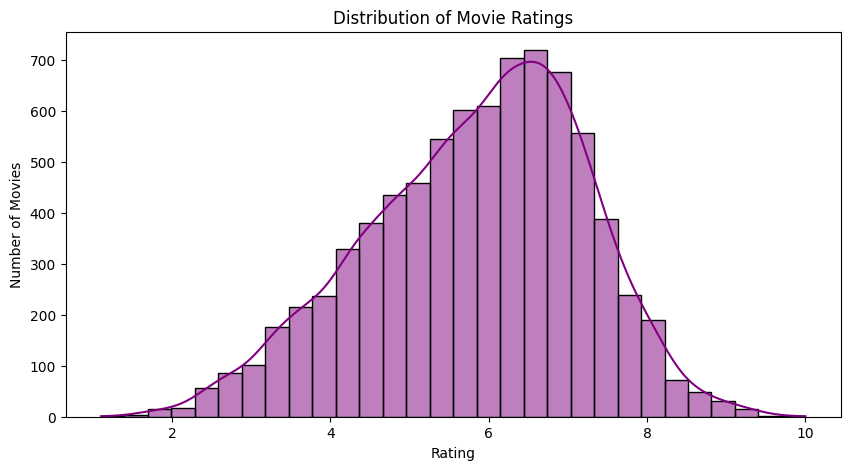

In [68]:
#visualization
plt.figure(figsize=(10, 5))
sns.histplot(df['Rating'], bins=30, kde=True, color='purple')
plt.title('Distribution of Movie Ratings')
plt.xlabel('Rating')
plt.ylabel('Number of Movies')
plt.show()

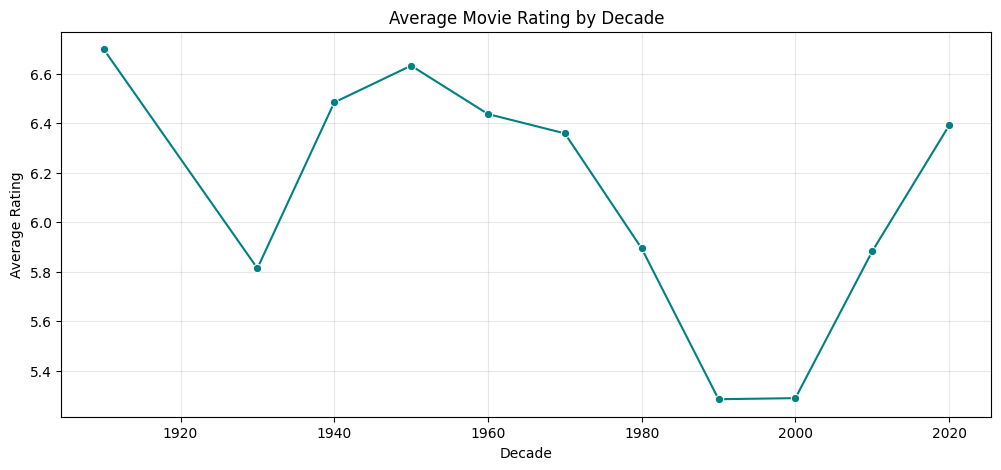

In [69]:
# average rating by decade

df['Decade'] = (df['Year'] // 10) * 10

plt.figure(figsize=(12, 5))
decade_avg = df.groupby('Decade')['Rating'].mean()
sns.lineplot(x=decade_avg.index, y=decade_avg.values, marker='o', color='teal')
plt.title('Average Movie Rating by Decade')
plt.xlabel('Decade')
plt.ylabel('Average Rating')
plt.grid(True, alpha=0.3)
plt.show()

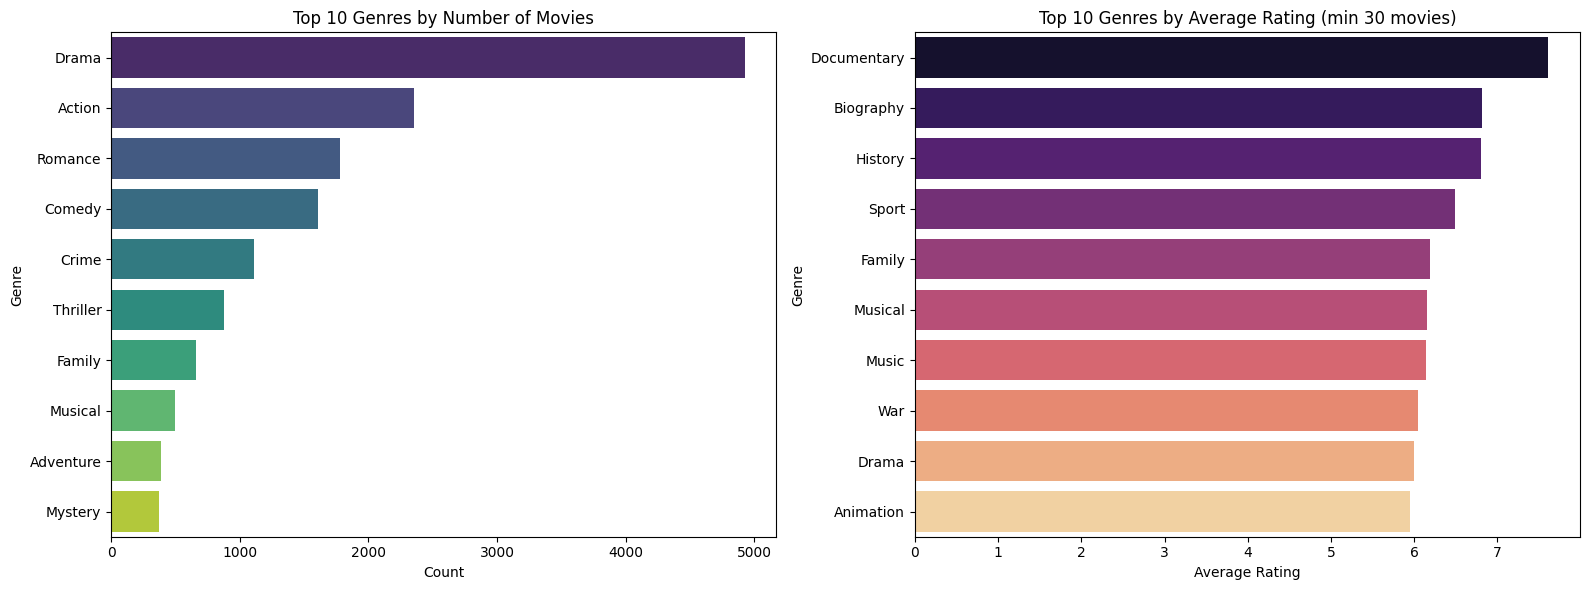

In [70]:
# Visualization 3, top genres by number of movies and by average rating
# Split "Drama, Romance" into separate genre rows
genre_df = df.assign(Genre=df['Genre'].str.split(', ')).explode('Genre')
genre_df = genre_df[genre_df['Genre'] != 'Unknown']

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

top_count = genre_df['Genre'].value_counts().head(10)
sns.barplot(x=top_count.values, y=top_count.index, ax=axes[0], palette='viridis')
axes[0].set_title('Top 10 Genres by Number of Movies')
axes[0].set_xlabel('Count')

genre_stats = genre_df.groupby('Genre')['Rating'].agg(['mean', 'count'])
top_rated = genre_stats[genre_stats['count'] >= 30]['mean'].sort_values(ascending=False).head(10)
sns.barplot(x=top_rated.values, y=top_rated.index, ax=axes[1], palette='magma')
axes[1].set_title('Top 10 Genres by Average Rating (min 30 movies)')
axes[1].set_xlabel('Average Rating')

plt.tight_layout()
plt.show()


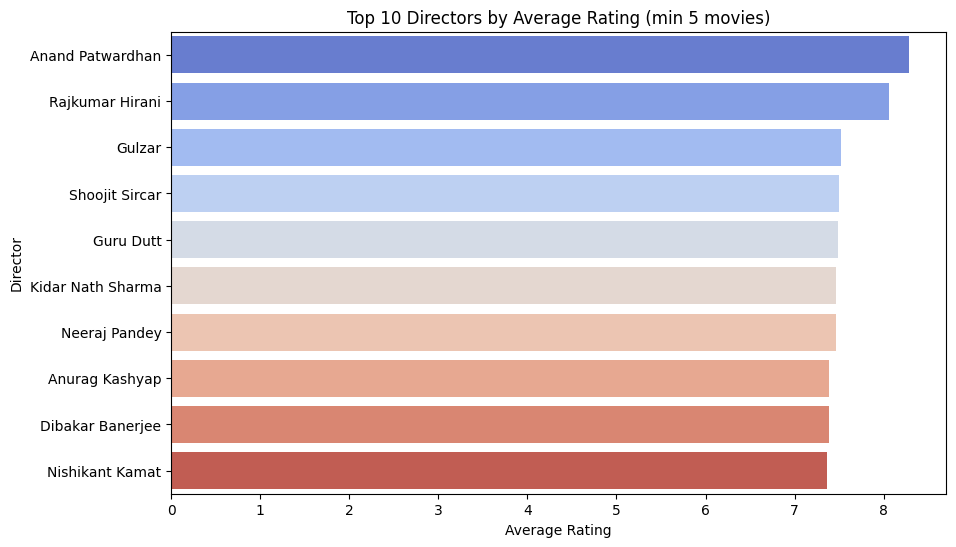

In [71]:
# Visualization 4, top directors by average rating
dir_stats = df[df['Director'] != 'Unknown'].groupby('Director')['Rating'].agg(['mean', 'count'])
top_dirs = dir_stats[dir_stats['count'] >= 5]['mean'].sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_dirs.values, y=top_dirs.index, palette='coolwarm')
plt.title('Top 10 Directors by Average Rating (min 5 movies)')
plt.xlabel('Average Rating')
plt.show()

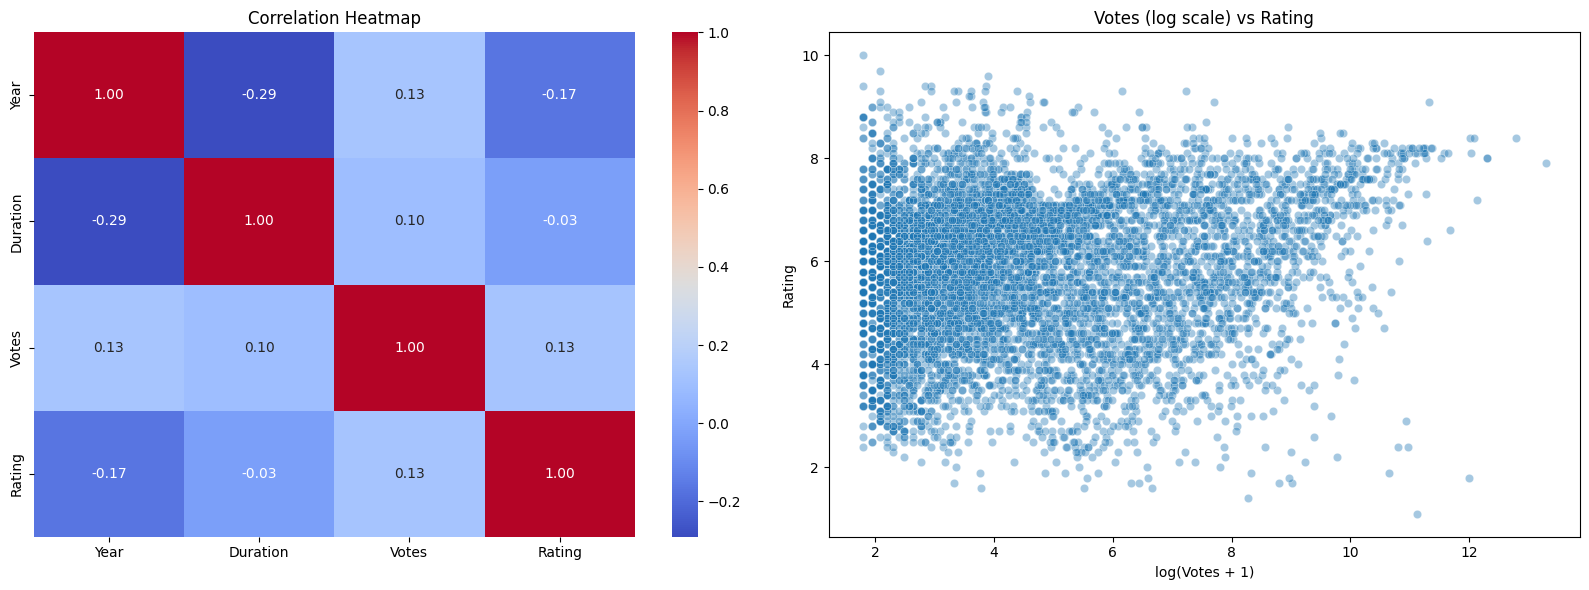

In [72]:
#Visualization 5, correlation heatmap and votes vs rating
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

corr = df[['Year', 'Duration', 'Votes', 'Rating']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', ax=axes[0])
axes[0].set_title('Correlation Heatmap')

sns.scatterplot(x=np.log1p(df['Votes']), y=df['Rating'], alpha=0.4, ax=axes[1])
axes[1].set_title('Votes (log scale) vs Rating')
axes[1].set_xlabel('log(Votes + 1)')

plt.tight_layout()
plt.show()

In [73]:
# train test split
from sklearn.model_selection import train_test_split

# Multi-hot encode genre
genre_dummies = df['Genre'].str.get_dummies(sep=', ')
genre_dummies = genre_dummies.loc[:, genre_dummies.sum() >= 50]
print("Genre columns kept:", genre_dummies.shape[1])

# Base feature
base = pd.concat(
    [df[['Year', 'Duration', 'Votes', 'Director', 'Actor 1', 'Actor 2', 'Actor 3']],
     genre_dummies], axis=1
)
base['Log_Votes'] = np.log1p(base['Votes'])
y = df['Rating']


X_train, X_test, y_train, y_test = train_test_split(
    base, y, test_size=0.2, random_state=42
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Genre columns kept: 19
Train: (6335, 27) | Test: (1584, 27)


In [74]:
#Train
m = 5
g = y_train.mean()
actor_cols = ['Actor 1', 'Actor 2', 'Actor 3']

def fit_stats(keys, target):
    tmp = pd.DataFrame({'k': keys.values, 'y': target.values})
    tmp = tmp[tmp['k'] != 'Unknown']
    return tmp.groupby('k')['y'].agg(['sum', 'count'])

def encode(keys, stats, target=None):
    s = keys.map(stats['sum']).fillna(0).values
    c = keys.map(stats['count']).fillna(0).values
    if target is not None:
        known = keys.isin(stats.index).values
        s = np.where(known, s - target.values, 0)
        c = np.where(known, c - 1, 0)
    return (s + m * g) / (c + m)

# Director
dir_stats = fit_stats(X_train['Director'], y_train)
X_train['Director_Enc'] = encode(X_train['Director'], dir_stats, y_train)
X_test['Director_Enc'] = encode(X_test['Director'], dir_stats)

# Actors
act_keys = pd.concat([X_train[c] for c in actor_cols])
act_y = pd.concat([y_train] * 3)
act_stats = fit_stats(act_keys, act_y)

for c in actor_cols:
    X_train[c + '_Enc'] = encode(X_train[c], act_stats, y_train)
    X_test[c + '_Enc'] = encode(X_test[c], act_stats)

enc_cols = [c + '_Enc' for c in actor_cols]
for data in (X_train, X_test):
    data['Actor_Enc_Mean'] = data[enc_cols].mean(axis=1)
    data['Actor_Enc_Max'] = data[enc_cols].max(axis=1)

X_train[['Director_Enc', 'Actor_Enc_Mean', 'Actor_Enc_Max']].describe()

,Director_Enc,Actor_Enc_Mean,Actor_Enc_Max
count,6335.000000,6335.000000,6335.000000
mean,5.840604,5.814669,6.083177
std,0.398802,0.324471,0.358244
min,4.429591,4.717579,4.795609
25%,5.669015,5.605255,5.831018
50%,5.831018,5.831018,6.042515
75%,6.025848,6.027000,6.359123
max,7.195509,6.761907,7.101836


In [75]:
# features
drop_cols = ['Director', 'Actor 1', 'Actor 2', 'Actor 3', 'Votes']
X_train = X_train.drop(columns=drop_cols)
X_test = X_test.drop(columns=drop_cols)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("\nFeatures used:\n", list(X_train.columns))
X_train.head()

X_train: (6335, 28)
X_test: (1584, 28)

Features used:
 ['Year', 'Duration', 'Action', 'Adventure', 'Animation', 'Biography', 'Comedy', 'Crime', 'Documentary', 'Drama', 'Family', 'Fantasy', 'History', 'Horror', 'Music', 'Musical', 'Mystery', 'Romance', 'Sport', 'Thriller', 'Unknown', 'Log_Votes', 'Director_Enc', 'Actor 1_Enc', 'Actor 2_Enc', 'Actor 3_Enc', 'Actor_Enc_Mean', 'Actor_Enc_Max']


,Year,Duration,Action,Adventure,Animation,Biography,Comedy,Crime,Documentary,Drama,...,Sport,Thriller,Unknown,Log_Votes,Director_Enc,Actor 1_Enc,Actor 2_Enc,Actor 3_Enc,Actor_Enc_Mean,Actor_Enc_Max
4252,2019,74.0,0,0,0,0,1,0,0,1,...,0,0,0,2.397895,6.109182,6.109182,5.831018,5.831018,5.923739,6.109182
4428,1981,134.0,0,0,0,0,0,0,0,1,...,0,0,0,2.833213,5.251620,6.367177,6.315748,5.607730,6.096885,6.367177
7373,2017,136.0,0,0,0,0,0,0,0,1,...,0,0,0,9.785548,6.215509,5.432653,4.609123,5.963825,5.335200,5.963825
1410,2003,117.0,1,0,0,0,0,0,0,0,...,0,0,0,2.890372,5.309182,5.350463,5.355667,4.808616,5.171582,5.355667
7895,1988,120.0,0,0,0,1,0,0,1,0,...,0,0,0,3.526361,6.125848,6.394434,6.262731,5.831018,6.162728,6.394434


In [76]:
# model
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

models = {
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=200, learning_rate=0.05, random_state=42)
}

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    results.append({
        'Model': name,
        'MAE': mean_absolute_error(y_test, pred),
        'RMSE': np.sqrt(mean_squared_error(y_test, pred)),
        'R2': r2_score(y_test, pred)
    })

results_df = pd.DataFrame(results).sort_values('R2', ascending=False)
results_df.round(3)

,Model,MAE,RMSE,R2
2,Gradient Boosting,0.785,1.034,0.425
1,Random Forest,0.794,1.045,0.412
0,Linear Regression,0.848,1.103,0.345


In [77]:
# without votes
X_train_nv = X_train.drop(columns=['Log_Votes'])
X_test_nv = X_test.drop(columns=['Log_Votes'])

rf_nv = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
rf_nv.fit(X_train_nv, y_train)
pred_nv = rf_nv.predict(X_test_nv)

print("Random Forest WITHOUT Votes")
print("MAE :", round(mean_absolute_error(y_test, pred_nv), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, pred_nv)), 3))
print("R2  :", round(r2_score(y_test, pred_nv), 3))

Random Forest WITHOUT Votes
MAE : 0.857
RMSE: 1.117
R2  : 0.328


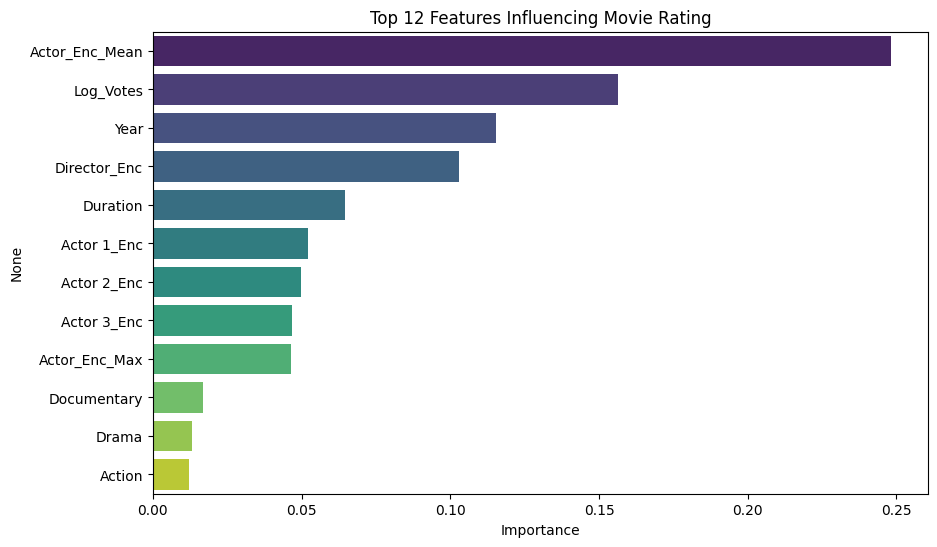

In [78]:
#feature
best = models['Random Forest']
imp = pd.Series(best.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(12)

plt.figure(figsize=(10, 6))
sns.barplot(x=imp.values, y=imp.index, palette='viridis')
plt.title('Top 12 Features Influencing Movie Rating')
plt.xlabel('Importance')
plt.show()

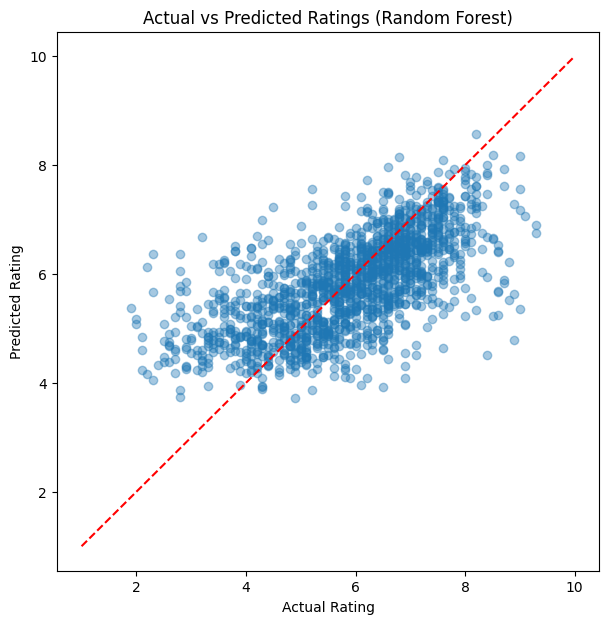

In [79]:
#actual vs predicted
pred_best = best.predict(X_test)

plt.figure(figsize=(7, 7))
plt.scatter(y_test, pred_best, alpha=0.4)
plt.plot([1, 10], [1, 10], 'r--')
plt.xlabel('Actual Rating')
plt.ylabel('Predicted Rating')
plt.title('Actual vs Predicted Ratings (Random Forest)')
plt.show()

In [80]:
# testing
demo = X_test.copy()
demo['Movie'] = df.loc[X_test.index, 'Name'].values
demo['Actual Rating'] = y_test.values
demo['Predicted Rating'] = models['Gradient Boosting'].predict(X_test).round(1)
demo['Error'] = (demo['Predicted Rating'] - demo['Actual Rating']).abs().round(1)

demo[['Movie', 'Actual Rating', 'Predicted Rating', 'Error']].head(10)

,Movie,Actual Rating,Predicted Rating,Error
4896,Mohabbat Pehli Nazar Mein,3.3,4.6,1.3
7538,Veerappan,5.3,5.4,0.1
1677,Commando 3,5.7,5.1,0.6
1964,Dhoop,7.2,5.5,1.7
3025,Horror Night,3.5,5.3,1.8
6260,Saheb Biwi Aur Gangster,7.2,5.8,1.4
6306,Sameera,3.8,5.8,2.0
2436,Fashion,6.9,6.4,0.5
4526,Main Suhagan Hoon,5.2,5.8,0.6
2464,Firaaq,7.4,6.8,0.6


## Conclusion

- Cleaned the IMDb Indian Movies dataset (15,509 rows → 7,919 rated movies) and engineered features from genre, director and actors.
- Compared three regression models. Gradient Boosting performed best (MAE ≈ 0.79, RMSE ≈ 1.03, R² ≈ 0.43).
- Without the Votes feature (a realistic pre-release scenario), Random Forest scored R² ≈ 0.33, MAE ≈ 0.86.
- Most influential factors: the actors' past average ratings, number of votes, release year and the director's track record. Genre had the smallest effect.
- Limitation: ratings are subjective and depend on factors not in the data (story, music, marketing), so R² of around 0.4 is reasonable.
